# Dar_005 — P1 radiation observations and published scenarios
**D07:** two CRaTER L2 SEC daily files; **D08:** two GOES-16 SGPS five-minute products;
**D31:** author-deposited monthly CRaTER comparison and modeled shielding/depth profiles.

Explore sampling, detector/control states, proton channels, valid-interval fluence, and
published scenario sensitivity. These are separate instruments/locations/quantities;
they are not merged as crew surface dose.

In [1]:
from pathlib import Path
import sys, json, io, re, zipfile
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p/'outline.md').is_file() and (p/'notebooks').is_dir())
sys.path[:0] = [str(ROOT/'darrel stuff/EDA'),str(ROOT)]
DATA = ROOT/'darrel stuff/data'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from environment_workflow import LocalRun as Run, latest_completed_run
from notebooks.shared.inspection import verify_run, check_input
from research_p1_readers import (pilot_files, pin_source, read_pds4, pds4_chunks,
    pds4_definition, pds4_image, dose_profiles, pds3_number)
import research_p1_readers
def savefig(run, fig, name):
    fig.savefig(run.path(name+'.png'),dpi=140,bbox_inches='tight')
    display(fig); plt.close(fig)
def save_findings(run, findings):
    run.path('findings.json').write_text(json.dumps(findings,indent=2,default=str),encoding='utf-8')
    display(Markdown('**Executed findings**')); display(findings)
def pin(run, path): return pin_source(run, path)
def short(region): return region.split('_',2)[-1].replace('_',' ')

## Quality, units and interpretation
CRaTER SEC files contain **counters and instrument/geometry state**, not LET spectra.
Report those available quantities; LET/event spectral EDA remains a product-selection gap.
GOES keeps the two sensor look directions separate, using label energy bounds in keV.
Strict differential averages require positive finite flux, at least 300 valid source
samples, zero dtc/oob/err DQF sums and the documented LUT match indicator. Fluence is only
the contribution from accepted 300-second intervals, not an event-total estimate over gaps.
REDMoon absorbed dose rate (cGy/year) and modeled effective dose (cSv/year) remain distinct.

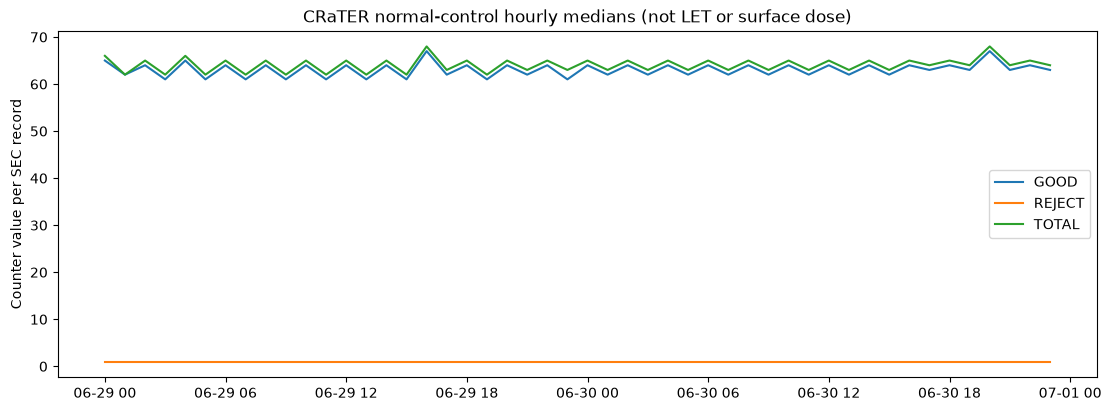

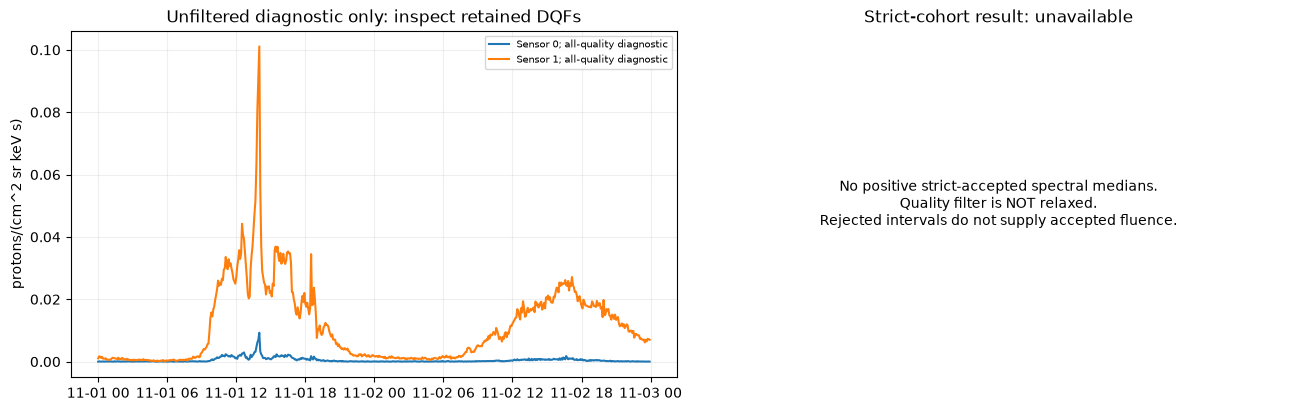

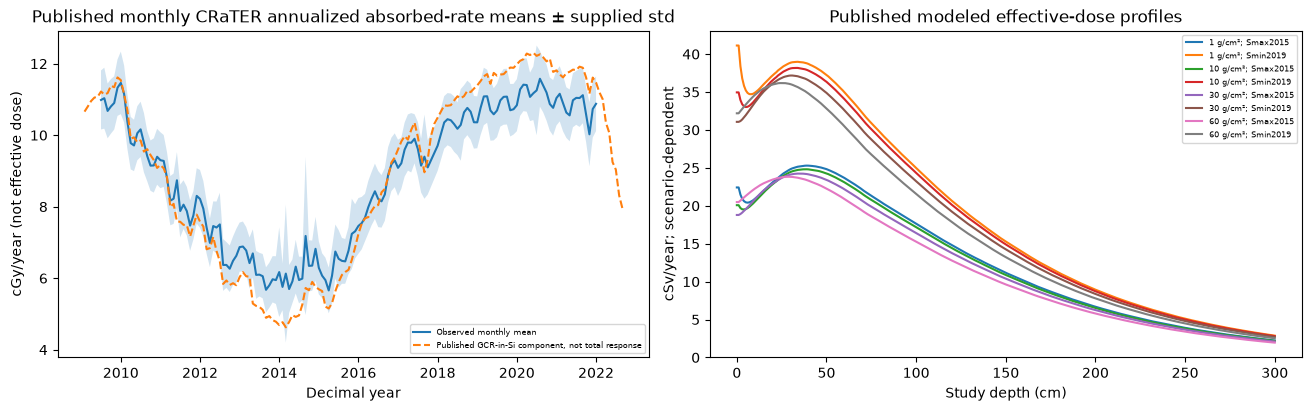

**Executed findings**

{'crater_rows': 172800,
 'normal_control_rows': 172800,
 'crater_time_gaps': {'CRAT_L2_SEC_2009180_V01': 0,
  'CRAT_L2_SEC_2009181_V01': 0},
 'goes_channel_time_rows': 14976,
 'accepted_goes_rows': 0,
 'goes_err_flagged_rows': 14976,
 'published_monthly_rows': 148,
 'published_modeled_monthly_rows': 164,
 'matched_observed_modeled_months': 148,
 'published_scenario_depth_rows': 14448,
 'published_scenarios': 48,
 'remaining': ['CRaTER LET/event spectra not present in SEC pilots',
  'No event-total fluence across rejected intervals; this pilot has no strict accepted rows',
  'No project radiation transport or approved crew limits']}

,sensor,channel,lower_energy_keV,upper_energy_keV,total_rows,accepted_rows,median,max,accepted_flux_sum,accepted_interval_fluence_protons_cm2_sr_keV
0,0,0,1020.0,1860.0,576,0,NaN,NaN,NaN,NaN
1,0,1,1900.0,2300.0,576,0,NaN,NaN,NaN,NaN
2,0,2,2310.0,3340.0,576,0,NaN,NaN,NaN,NaN
3,0,3,3400.0,6480.0,576,0,NaN,NaN,NaN,NaN
4,0,4,5840.0,11000.0,576,0,NaN,NaN,NaN,NaN
5,0,5,11640.0,23270.0,576,0,NaN,NaN,NaN,NaN
6,0,6,24900.0,38100.0,576,0,NaN,NaN,NaN,NaN
7,0,7,40300.0,73400.0,576,0,NaN,NaN,NaN,NaN
8,0,8,83700.0,98500.0,576,0,NaN,NaN,NaN,NaN
9,0,9,99900.0,118000.0,576,0,NaN,NaN,NaN,NaN


Completed: C:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\darrel stuff\data\processed\analysis\dar_005_research_radiation\20261107T160219935579Z_f7779c


In [2]:
import netCDF4 as nc
with Run(ROOT,'analysis/dar_005_research_radiation',{'datasets':['D07','D08','D31'],'scope':'two-day pilots and published study tables'},'Moon/Dar_005_research_radiation.ipynb') as run:
    run.input(Path(research_p1_readers.__file__))
    crater=[]
    for label in pilot_files(DATA,'D07','.xml'):
        pin(run,label);pin(run,label.with_suffix('.TAB'));f=read_pds4(label)
        f['timestamp']=pd.to_datetime(f.TIME,utc=True);f['source_product']=label.stem
        f['normal_control']=f.BIASCMD.eq(1)&f.CALLOW.eq(0)&f.CALHIGH.eq(0)&f[[f'PROCDFLAG {i}' for i in range(1,7)]].eq(1).all(axis=1)
        crater.append(f)
    crater=pd.concat(crater,ignore_index=True)
    states=crater.groupby(['source_product','BIASCMD','CALLOW','CALHIGH','normal_control']).size().rename('rows').reset_index()
    states.to_csv(run.path('crater_instrument_states.csv'),index=False)
    counters=['GOOD','REJECT','TOTAL']+[f'SINGLE {i}' for i in range(1,7)]
    crater.groupby(['source_product','normal_control'])[counters].agg(['count','median','min','max']).to_csv(run.path('crater_counter_distributions.csv'))
    hourly=crater.loc[crater.normal_control].set_index('timestamp')[counters].resample('1h').median()
    hourly.to_csv(run.path('crater_hourly_counter_medians.csv'))
    gaps=crater.groupby('source_product').timestamp.apply(lambda s:int(s.sort_values().diff().dt.total_seconds().gt(1.01).sum()))
    fig,ax=plt.subplots(figsize=(11,4),layout='constrained')
    for field in ['GOOD','REJECT','TOTAL']:ax.plot(hourly.index,hourly[field],label=field)
    ax.set(ylabel='Counter value per SEC record',title='CRaTER normal-control hourly medians (not LET or surface dose)');ax.legend()
    savefig(run,fig,'crater_counters')
    goes=[];goes_coverage=[];attrs=[]
    for path in pilot_files(DATA,'D08','.nc'):
        pin(run,path)
        with nc.Dataset(path) as source:
            tv=source['L2_SciData_TimeStamp'];times=pd.to_datetime(nc.num2date(tv[:],tv.units,only_use_cftime_datetimes=False),utc=True)
            flux=np.ma.asarray(source['AvgDiffProtonFlux'][:]).astype(float).filled(np.nan)
            samples=np.ma.asarray(source['DiffValidL1bSamplesInAvg'][:]).astype(float).filled(np.nan)
            dqf=[np.ma.asarray(source[k][:]).astype(float).filled(np.nan) for k in ['DiffDQFdtcSum','DiffDQFoobSum','DiffDQFerrSum']]
            lut=int(source['ExpectedLUTNotFound'][...])
            low=np.ma.asarray(source['DiffProtonLowerEnergy'][:]).astype(float).filled(np.nan)
            high=np.ma.asarray(source['DiffProtonUpperEnergy'][:]).astype(float).filled(np.nan)
            if source['AvgDiffProtonFlux'].units!='protons/(cm^2 sr keV s)':raise ValueError('Unconfirmed GOES flux units')
            attrs.append({'file':path.name,'flux_unit':source['AvgDiffProtonFlux'].units,'LUT_indicator':lut,
                          'LUT_description':source['ExpectedLUTNotFound'].long_name})
            for sensor in range(flux.shape[1]):
                for channel in range(flux.shape[2]):
                    values=flux[:,sensor,channel]
                    good=np.isfinite(values)&(values>=0)&(samples[:,sensor,channel]>=300)&(lut==1)
                    for flag in dqf:good &= flag[:,sensor,channel]==0
                    goes.append(pd.DataFrame({'timestamp':times,'source_product':path.stem,'sensor':sensor,
                        'channel':channel,'lower_energy_keV':low[sensor,channel],'upper_energy_keV':high[sensor,channel],
                        'flux':values,'strict_quality':good,'source_samples':samples[:,sensor,channel],
                        'dqf_dtc_sum':dqf[0][:,sensor,channel],'dqf_oob_sum':dqf[1][:,sensor,channel],
                        'dqf_err_sum':dqf[2][:,sensor,channel],'lut_match_indicator':lut}))
            goes_coverage.append({'file':path.name,'timestamps':len(times),'gaps_not_300s':int((pd.Series(times).diff().dt.total_seconds().dropna()!=300).sum())})
    goes=pd.concat(goes,ignore_index=True)
    goes.to_csv(run.path('goes_differential_observations.csv'),index=False)
    summary=goes.groupby(['sensor','channel','lower_energy_keV','upper_energy_keV']).agg(total_rows=('flux','size'),accepted_rows=('strict_quality','sum')).reset_index()
    good=goes.loc[goes.strict_quality]
    accepted=good.groupby(['sensor','channel']).flux.agg(['median','max','sum']).rename(columns={'sum':'accepted_flux_sum'}).reset_index()
    accepted['accepted_interval_fluence_protons_cm2_sr_keV']=accepted.accepted_flux_sum*300
    summary=summary.merge(accepted,on=['sensor','channel'],how='left',validate='one_to_one')
    summary.to_csv(run.path('goes_channel_quality_fluence.csv'),index=False)
    pd.DataFrame(goes_coverage).to_csv(run.path('goes_time_coverage.csv'),index=False)
    run.path('goes_metadata.json').write_text(json.dumps(attrs,indent=2),encoding='utf-8')
    fig,axes=plt.subplots(1,2,figsize=(13,4),layout='constrained')
    for sensor,part in goes.loc[goes.channel.eq(0)].groupby('sensor'):
        axes[0].plot(part.timestamp,part.flux,label=f'Sensor {sensor}; all-quality diagnostic')
    axes[0].set(title='Unfiltered diagnostic only: inspect retained DQFs',ylabel='protons/(cm^2 sr keV s)')
    positive=summary.loc[summary['median'].gt(0)]
    if len(positive):
        for sensor,part in positive.groupby('sensor'):
            axes[1].plot((part.lower_energy_keV*part.upper_energy_keV)**.5,part['median'],marker='.',label=f'Sensor {sensor}')
        axes[1].set(title='Strict accepted median spectrum',xlabel='Channel geometric-center energy (keV)',ylabel='Differential proton flux',xscale='log',yscale='log')
        axes[1].legend()
    else:
        axes[1].text(.5,.5,'No positive strict-accepted spectral medians.\nQuality filter is NOT relaxed.\nRejected intervals do not supply accepted fluence.',ha='center',va='center',transform=axes[1].transAxes)
        axes[1].set_title('Strict-cohort result: unavailable');axes[1].set_axis_off()
    axes[0].legend(fontsize=7)
    for ax in axes:ax.grid(alpha=.2)
    diagnostic=goes.groupby(['sensor','channel']).agg(raw_finite_rows=('flux','count'),strict_accepted_rows=('strict_quality','sum'),
        err_flagged_rows=('dqf_err_sum',lambda v:v.gt(0).sum()),diagnostic_median_flux=('flux','median')).reset_index()
    diagnostic.to_csv(run.path('goes_flagged_diagnostic_summary.csv'),index=False)
    savefig(run,fig,'goes_protons')
    files=pilot_files(DATA,'D31','.txt')
    monthly_path=next(p for p in files if p.name=='CRaTER.txt');profile_path=next(p for p in files if p.name.startswith('Figure1'))
    pin(run,monthly_path);pin(run,profile_path)
    from research_p1_readers import published_crater_tables
    monthly,modeled_monthly=published_crater_tables(monthly_path)
    modeled_monthly.to_csv(run.path('published_modeled_monthly_components.csv'),index=False)
    monthly_comparison=monthly.merge(modeled_monthly,on='decimal_year',validate='one_to_one')
    monthly_comparison.to_csv(run.path('published_observed_modeled_month_overlap.csv'),index=False)
    profiles=dose_profiles(profile_path)
    if profiles.duplicated(['al_g_cm2','solar_scenario','particles','depth_cm']).any():raise ValueError('Duplicate model scenario/depth')
    monthly.to_csv(run.path('published_crater_monthly_rates.csv'),index=False)
    profiles.to_csv(run.path('published_dose_depth_scenarios.csv'),index=False)
    all_particles=profiles.loc[profiles.particles.eq('all')]
    baseline=all_particles.loc[all_particles.al_g_cm2.eq(all_particles.al_g_cm2.min())].drop(columns='al_g_cm2').rename(columns={'effective_dose_cSv_year':'reference_effective_dose_cSv_year'})
    comparison=all_particles.merge(baseline,on=['solar_scenario','particles','depth_cm'],validate='many_to_one')
    comparison['relative_to_minimum_published_Al']=comparison.effective_dose_cSv_year/comparison.reference_effective_dose_cSv_year
    comparison.to_csv(run.path('published_shielding_sensitivity.csv'),index=False)
    fig,axes=plt.subplots(1,2,figsize=(13,4),layout='constrained')
    axes[0].plot(monthly.decimal_year,monthly.absorbed_rate_cGy_year,label='Observed monthly mean')
    axes[0].plot(modeled_monthly.decimal_year,modeled_monthly.GCR_in_Si_cGy_year,linestyle='--',label='Published GCR-in-Si component, not total response')
    axes[0].legend(fontsize=6)
    axes[0].fill_between(monthly.decimal_year,monthly.absorbed_rate_cGy_year-monthly.std_cGy_year,monthly.absorbed_rate_cGy_year+monthly.std_cGy_year,alpha=.2)
    axes[0].set(title='Published monthly CRaTER annualized absorbed-rate means ± supplied std',xlabel='Decimal year',ylabel='cGy/year (not effective dose)')
    for (al,solar),part in all_particles.groupby(['al_g_cm2','solar_scenario']):axes[1].plot(part.depth_cm,part.effective_dose_cSv_year,label=f'{al} g/cm²; {solar}')
    axes[1].set(title='Published modeled effective-dose profiles',xlabel='Study depth (cm)',ylabel='cSv/year; scenario-dependent')
    axes[1].legend(fontsize=6);savefig(run,fig,'published_radiation_scenarios')
    save_findings(run,{'crater_rows':len(crater),'normal_control_rows':int(crater.normal_control.sum()),'crater_time_gaps':gaps.to_dict(),
        'goes_channel_time_rows':len(goes),'accepted_goes_rows':len(good),'goes_err_flagged_rows':int(goes.dqf_err_sum.gt(0).sum()),'published_monthly_rows':len(monthly),'published_modeled_monthly_rows':len(modeled_monthly),'matched_observed_modeled_months':len(monthly_comparison),
        'published_scenario_depth_rows':len(profiles),'published_scenarios':len(profiles[['al_g_cm2','solar_scenario','particles']].drop_duplicates()),
        'remaining':['CRaTER LET/event spectra not present in SEC pilots','No event-total fluence across rejected intervals; this pilot has no strict accepted rows','No project radiation transport or approved crew limits']})
    display(summary)
OUT=run.directory;print('Completed:',OUT)

## Stage 3 role
Keep instrument status, missing intervals, directional energy spectra and published study
assumptions as separate evidence. Quiet pilot days do not bound a future solar-particle
event. Neither Earth-orbit flux, orbital counters nor author-modeled shielding profiles
establish lunar crew dose, approved protection limits or hardware radiation tolerance.
M06 project-specific transport/protection outputs remain missing (Dar_011).